# Grafieken in R (deel 1)
We beginnen de cursus R met het maken van grafieken. Om dat te kunnen doen, installeren we eerst een verzameling ' R packages': de tidyverse. Onderdeel hiervan is het package ggplot waarmee we grafieken kunnen maken. 

In [22]:
install.packages("tidyverse")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘textshaping’, ‘ragg’


Warning message in install.packages("tidyverse"):
“installation of package ‘textshaping’ had non-zero exit status”
Warning message in install.packages("tidyverse"):
“installation of package ‘ragg’ had non-zero exit status”
Warning message in install.packages("tidyverse"):
“installation of package ‘tidyverse’ had non-zero exit status”


In [23]:
library(tidyverse)

Daarnaast installeren we een drietal datasets:<br>
- nycflights13 met data over vluchten die in 2013 vanaf New York City vertrokken<br>
- gapminder met data over het BNP per land<br>
- Lahman met data over honkbal

In [24]:
install.packages(c("nycflights13", "gapminder", "Lahman"))

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



Een met de tidyverse standaard geinstalleerde dataset is mpg:<br>
mpg contains observations collected by the US Environmental Protection Agency on 38 models of car. 

In [25]:
mpg

manufacturer,model,displ,year,cyl,trans,drv,cty,hwy,fl,class
<chr>,<chr>,<dbl>,<int>,<int>,<chr>,<chr>,<int>,<int>,<chr>,<chr>
audi,a4,1.8,1999,4,auto(l5),f,18,29,p,compact
audi,a4,1.8,1999,4,manual(m5),f,21,29,p,compact
audi,a4,2.0,2008,4,manual(m6),f,20,31,p,compact
audi,a4,2.0,2008,4,auto(av),f,21,30,p,compact
audi,a4,2.8,1999,6,auto(l5),f,16,26,p,compact
audi,a4,2.8,1999,6,manual(m5),f,18,26,p,compact
audi,a4,3.1,2008,6,auto(av),f,18,27,p,compact
audi,a4 quattro,1.8,1999,4,manual(m5),4,18,26,p,compact
audi,a4 quattro,1.8,1999,4,auto(l5),4,16,25,p,compact


Als je wilt weten wat de kolomnamen betekenen, typ je een vraagteken voor de naam van de dataset:

In [26]:
?mpg

## geom_point
Het eerste grafiektype is het spreidingsdiagram of scatter plot. Je gebruikt een spreidingsdiagram om het verband tussen 2 variabelen te laten zien. We gebruiken hier als voorbeeld het verband tussen de motorinhoud (displ, op de x-as) en het brandstofverbruik (hwy in gallons per mile, op de y-as).<br>
https://ggplot2.tidyverse.org/reference/geom_point.html

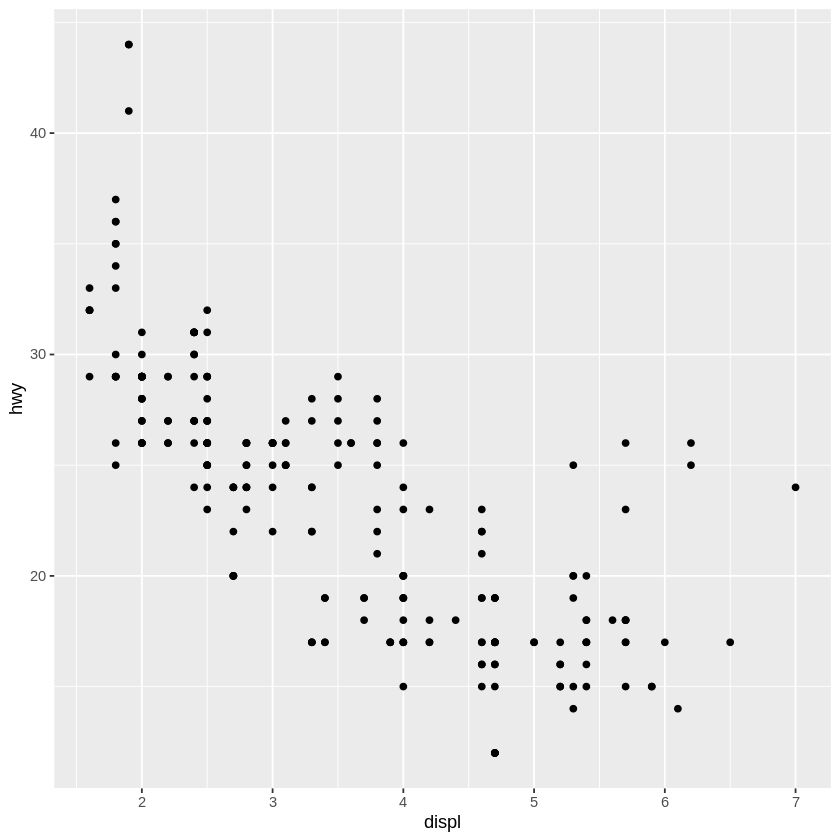

In [27]:
ggplot(data = mpg) + 
  geom_point(mapping = aes(x = displ, y = hwy))

We zien dat hoe groter de motorinhoud, hoe minder miles per gallon = hoe hoger het brandstofverbruik.<br>
Auto's met grote motoren zijn minder zuinig, zo lijkt het.

We kunnen aan het spreidingsdiagram een variabele toevoegen via de 'color' optie. We kiezen 'class' (= type auto) voor de color-variabele: 

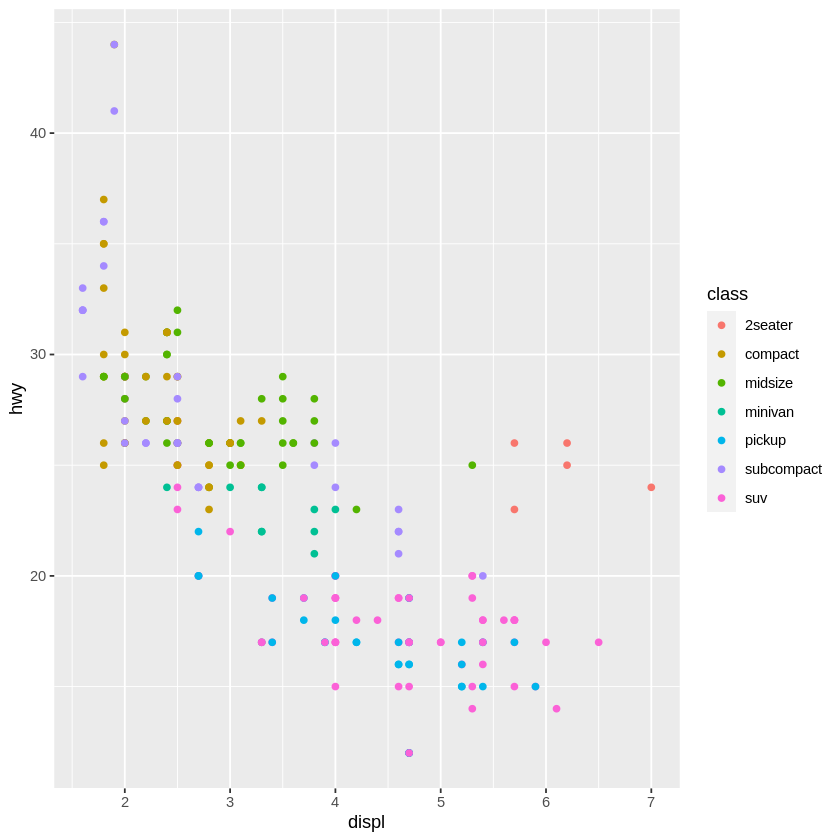

In [28]:
ggplot(data = mpg) + 
  geom_point(mapping = aes(x = displ, y = hwy, color = class))

Je ziet dat de SUV's en de pickup trucks wat minder zuinig zijn, en de subcompact en compact wat zuiniger.

In plaats van 'color' kunnen we ook 'size' toevoegen als variabele. We kiezen wederom 'class', nu voor de size-variabele:

Warning message:
“Using size for a discrete variable is not advised.”


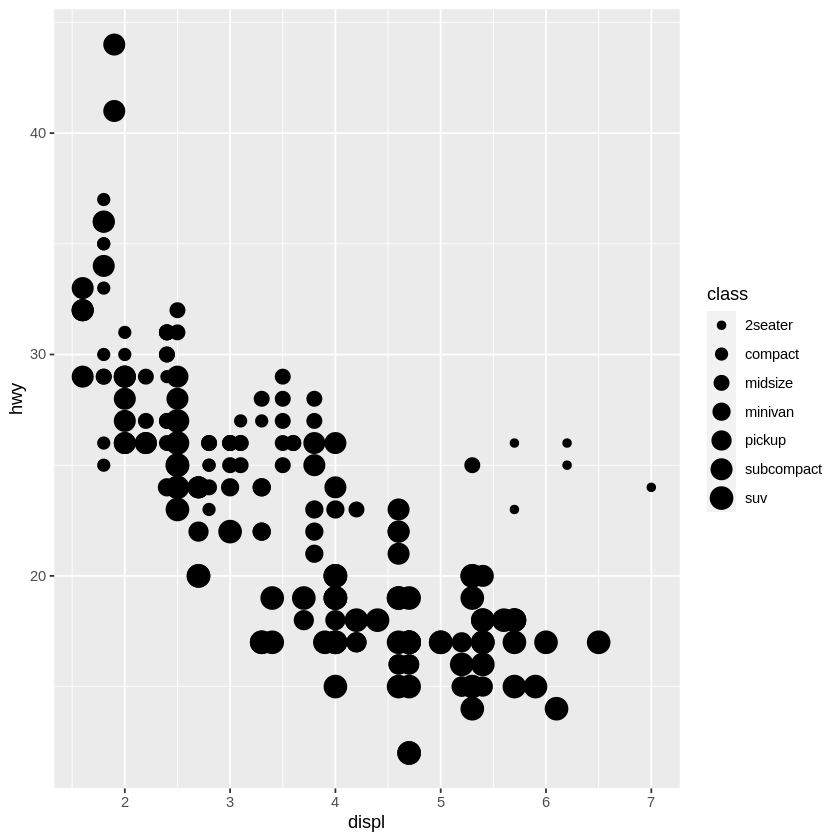

In [29]:
ggplot(data = mpg) + 
  geom_point(mapping = aes(x = displ, y = hwy, size = class))
#> Warning: Using size for a discrete variable is not advised.

De waarschuwing zegt het al: het is niet verstandig om bij de 'size'-variabele een discrete categorie in te vullen. 'Size' kun je beter gebruiken voor een continue variabele.

Onderstaand nog 2 voorbeelden van een spreidingsdiagram met een extra variabele:<br>
- alpha: te gebruiken om de punten een lichtere of donkerder grijstint te geven<br>
- shape: ggplot gebruikt 6 standaard vormen voor een datapunt (cirkel, driehoek, rechthoek, kruis, vierkant, ster).

Als er meer dan 6 categorieen zijn, zijn die niet zichtbaar in de grafiek (hieronder is de SUV niet zichtbaar). 

Warning message:
“Using alpha for a discrete variable is not advised.”
Warning message:
“The shape palette can deal with a maximum of 6 discrete values because
more than 6 becomes difficult to discriminate; you have 7. Consider
specifying shapes manually if you must have them.”
Warning message:
“Removed 62 rows containing missing values (`geom_point()`).”


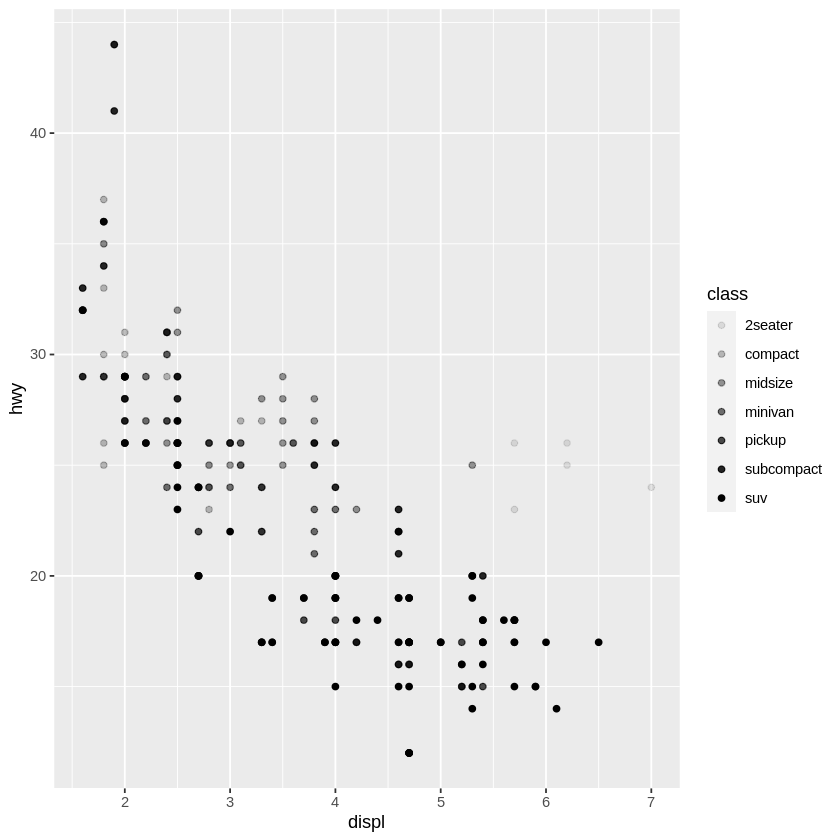

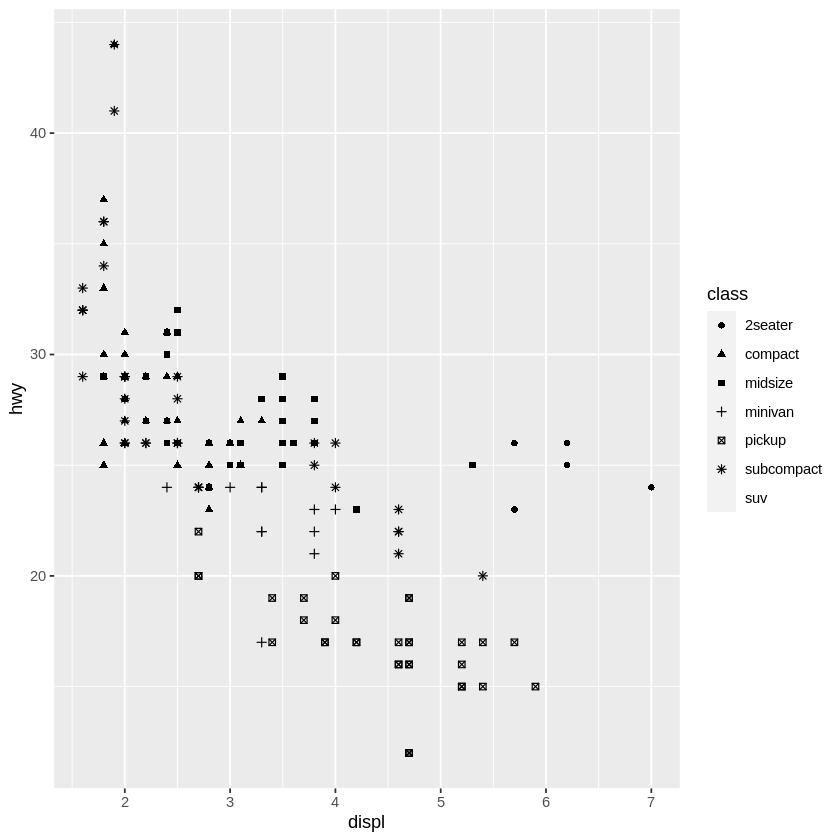

In [30]:
# Left
ggplot(data = mpg) + 
  geom_point(mapping = aes(x = displ, y = hwy, alpha = class))

# Right
ggplot(data = mpg) + 
  geom_point(mapping = aes(x = displ, y = hwy, shape = class))

We kunnen ook alle punten in de grafiek een kleur geven, dan moet je 'color' buiten de aes-haakjes zetten:

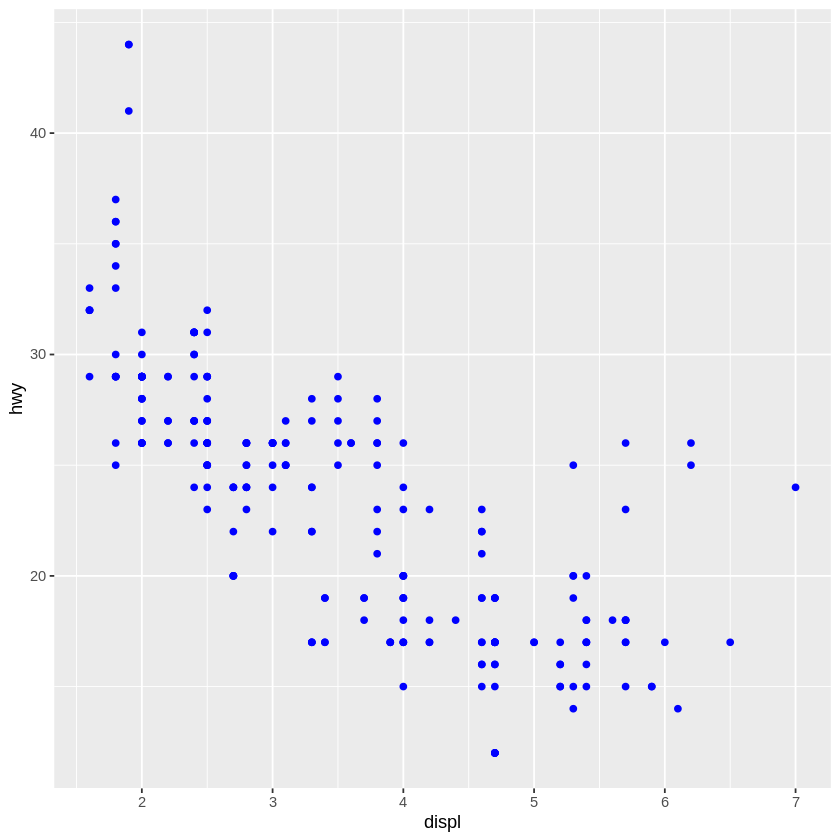

In [31]:
ggplot(data = mpg) + 
  geom_point(mapping = aes(x = displ, y = hwy), color = "blue")

En als we de verdeling van de punten wat beter willen zien, kunnen we met het 'jitter'-commando wat ruis aan de data toevoegen, waardoor we beter kunnen zien waar de grootste hoeveelheid datapunten zit:

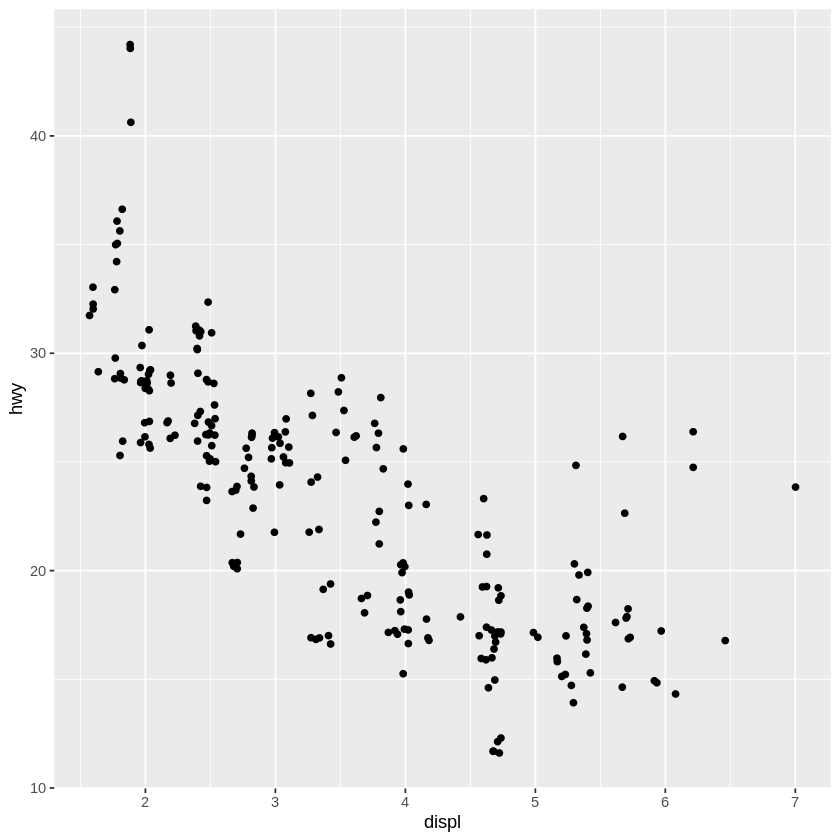

In [32]:
ggplot(data = mpg) + 
  geom_point(mapping = aes(x = displ, y = hwy), position = "jitter")

### facet_wrap_ 
Met facet_wrap kun je in plaats van 1 meerdere grafieken tegelijk maken. Als we per autotype het verband tussen motorinhoud en verbruik willen laten zien, gebruiken we de volgende code:

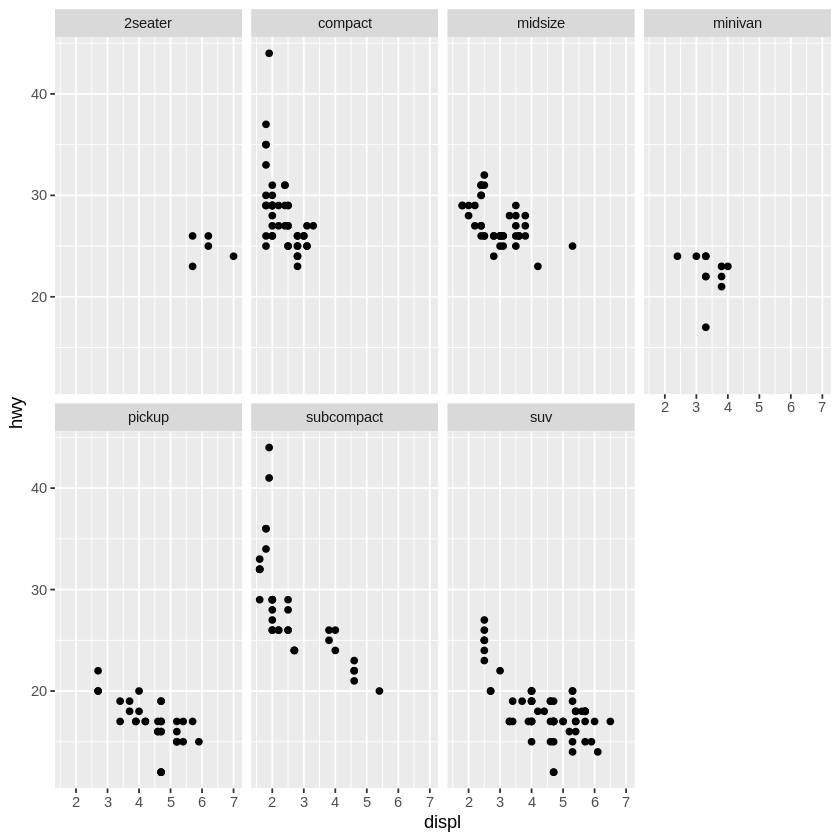

In [33]:
ggplot(data = mpg) + 
  geom_point(mapping = aes(x = displ, y = hwy)) + 
  facet_wrap(~ class, nrow = 2)

### facet_grid
Met facet_grid kun je nog een extra variabele toevoegen: we willen nog steeds het verband zien tussen motorinhoud en verbruik, maar nu zowel per soort aandrijving (drv: 4=four-wheel drive, f=front-wheel drive, r=rear-wheel drive) en per cylinderinhoud (cyl: 4, 5, 6 of 8 liter):


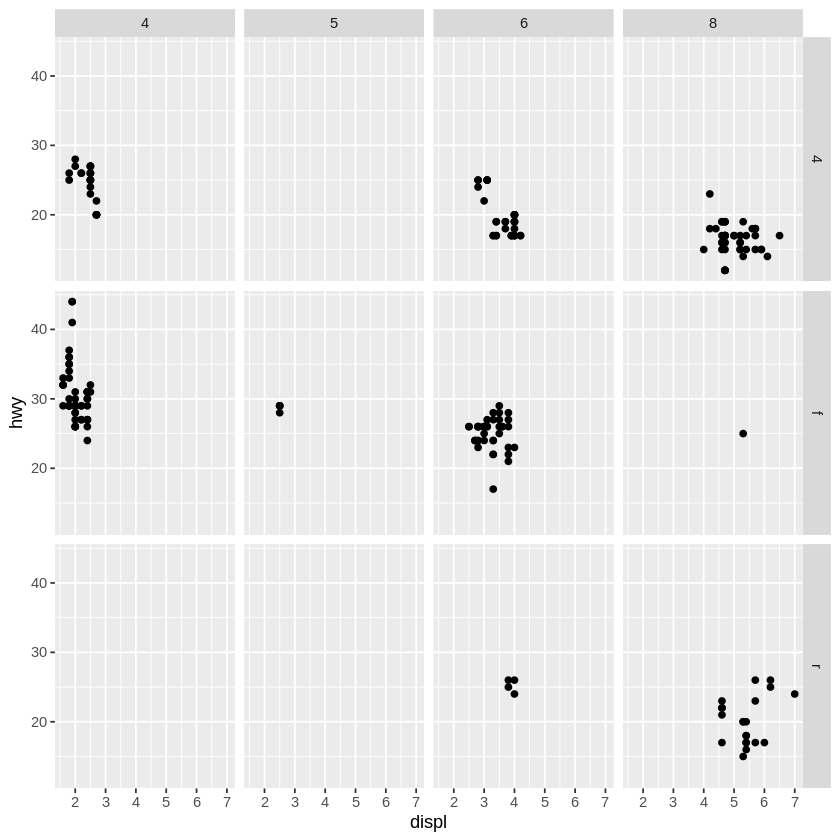

In [34]:
ggplot(data = mpg) + 
  geom_point(mapping = aes(x = displ, y = hwy)) + 
  facet_grid(drv ~ cyl)

Voor meer uitleg over het gebruik van facet_wrap (of facet_grid):<br>
typ een ? voor het commando.

In [35]:
?facet_wrap

## geom_line
Naast spreidingsdiagrammen kunnen we ook 'gewone' lijn-diagrammen maken. Deze zijn bijvoorbeeld zeer geschikt voor het maken van tijdreeksen.
<p>
We gebruiken als voorbeelddataset 'economics' met daarin data van de Amerikaanse economie:

In [36]:
?economics

In [37]:
economics

date,pce,pop,psavert,uempmed,unemploy
<date>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
1967-07-01,506.7,198712,12.6,4.5,2944
1967-08-01,509.8,198911,12.6,4.7,2945
1967-09-01,515.6,199113,11.9,4.6,2958
1967-10-01,512.2,199311,12.9,4.9,3143
1967-11-01,517.4,199498,12.8,4.7,3066
1967-12-01,525.1,199657,11.8,4.8,3018
1968-01-01,530.9,199808,11.7,5.1,2878
1968-02-01,533.6,199920,12.3,4.5,3001
1968-03-01,544.3,200056,11.7,4.1,2877


Wat is het verloop van het aantal werklozen gedurende de jaren 1970-2015?

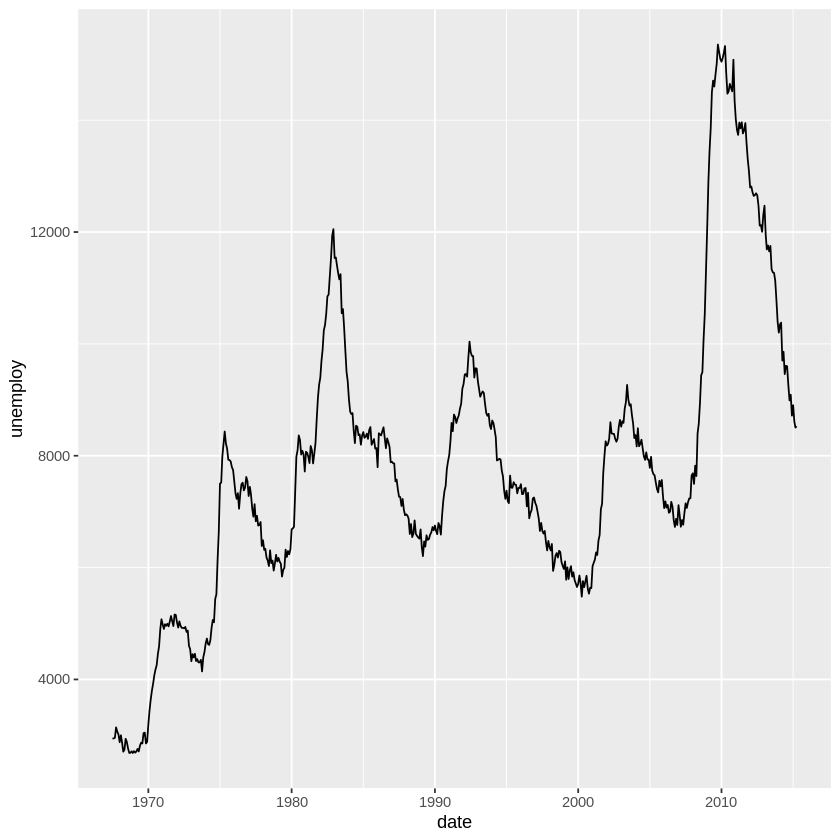

In [38]:
ggplot(data = economics) + 
  geom_line(mapping = aes(x = date, y = unemploy))

Of in verkorte vorm:

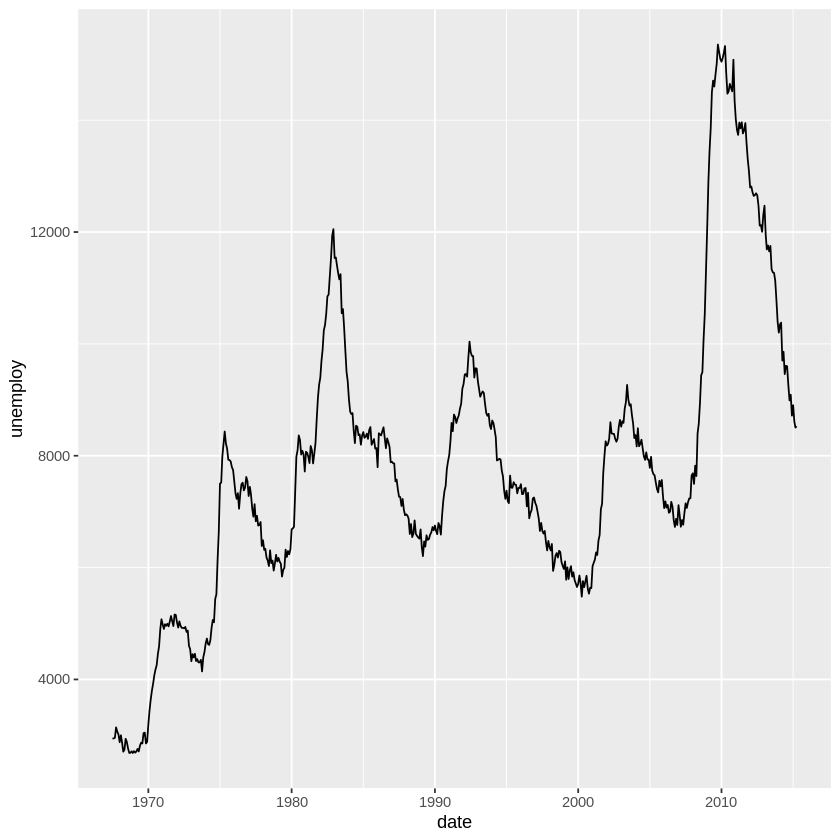

In [39]:
ggplot(economics, aes(date, unemploy)) + geom_line()

Voor meer voorbeelden van lijn-grafieken:<br>
https://ggplot2.tidyverse.org/reference/geom_path.html

## geom_bubble
We kunnen ook een bubbel-grafiek maken. Daarvoor gebruiken we de eerder ingeladen 'gapminder' dataset:<br>
https://www.gapminder.org/

In [40]:
# The dataset is provided in the gapminder library
library(gapminder)

We selecteren het jaar 2007 voor het maken van de grafiek:

In [41]:
data <- gapminder %>% filter(year=="2007") %>% dplyr::select(-year)

En maken vervolgens een 'bubble chart' van het BNP per hoofd van de bevolking op de x-as en de levensverwachting (in jaren) op de y-as:

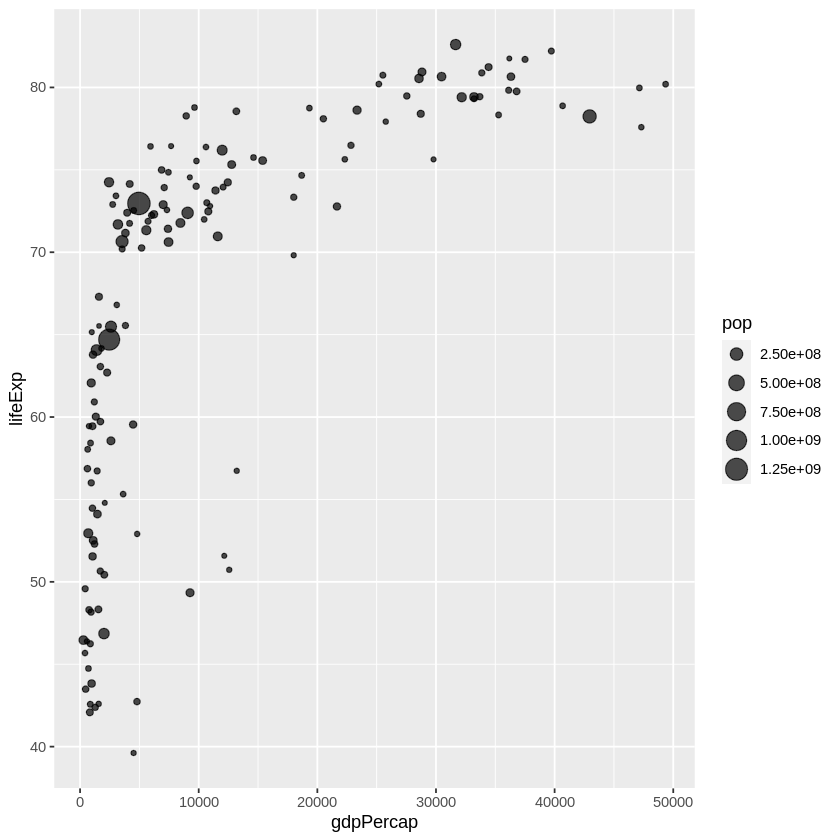

In [42]:
# Most basic bubble plot
ggplot(data, aes(x=gdpPercap, y=lifeExp, size = pop)) +
    geom_point(alpha=0.7)

Kan ie nog mooier? Dat kan:

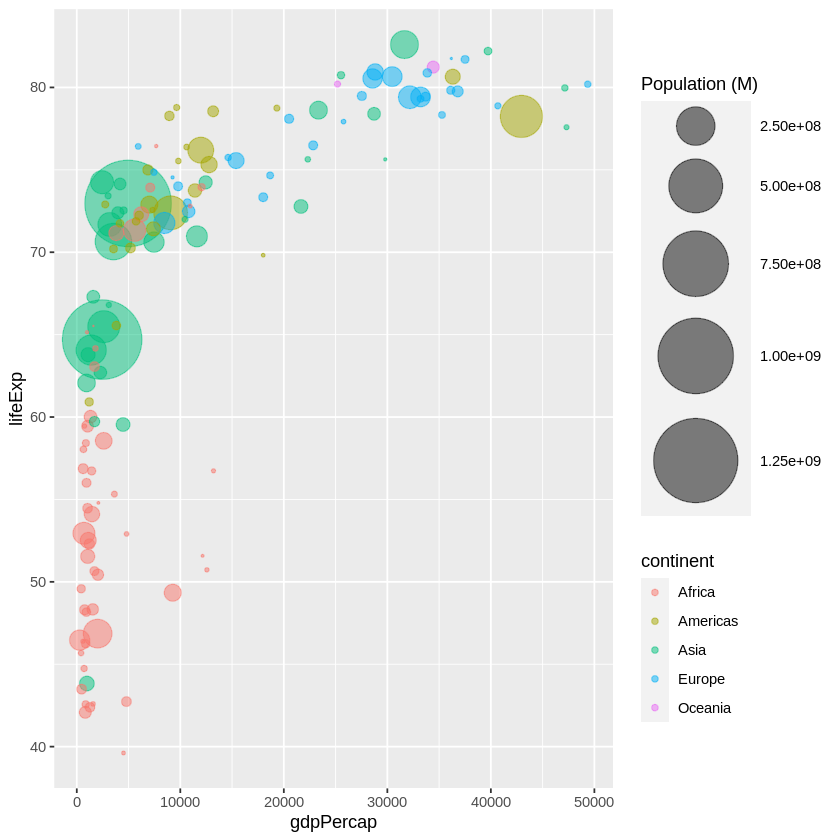

In [43]:
data %>%
  arrange(desc(pop)) %>%
  mutate(country = factor(country, country)) %>%
  ggplot(aes(x=gdpPercap, y=lifeExp, size=pop, color=continent)) +
    geom_point(alpha=0.5) +
    scale_size(range = c(.1, 24), name="Population (M)")

https://r-graph-gallery.com/320-the-basis-of-bubble-plot.html

# Huiswerk
Maak de opgaven uit het boek van paragraaf:<br>
- 3.2.4 (First Steps)<br>
- 3.3.1 (Aesthetic Mappings)<br>
- 3.5.1 (Facets)